# CODE 3.1: Crop the Gum

> **Goal:** cut every photo down to a smaller window around the gum, and cut its mask in exactly the same way. Then the models spend their pixels on the gum, not on the mat around it.
>
> - **Input:** the photos and masks in `data/raw/chewinggum/`, and the split files `splits/split_1.csv` to `splits/split_3.csv` (notebook 1.3)
> - **Output:** in the folder `data/processed/crops/`:
>   - `images/`: one cropped photo for every photo (PNG)
>   - `masks/`: one cropped mask for every defect photo (PNG)
>   - `crop_boxes.csv`: for every photo, where its gum is and where its window was cut
>
> Both models use these crops in step 4, and notebook 3.2 makes YOLO's boxes from the cropped masks.

### The Idea in Short

> 1. **Find the gum** in every photo: the box around its bright pixels (Step 1).
> 2. **Look at the top of the gum.** The light comes from below, so the top of the gum is darker, and the bright box misses it. How much? (Step 2)
> 3. **Choose one window size** for all photos: the biggest gum plus a margin, measured on the normal train photos only (Step 3).
> 4. **Place the window** on every photo, with the gum in the middle (Step 4).
> 5. **Check with the masks** that no defect is cut off (Step 5).
> 6. **Cut and save** the photos and masks (Step 6).
> 7. **See what we gain:** a thin crack in the whole photo against the same crack in the crop, at the same picture size (Step 7).

### Words Used in This Notebook

> - **Crop:** cut a rectangle out of a photo and throw the rest away.
> - **Window:** the rectangle we cut out. It has the same size in every photo, but its place follows the gum.
> - **Gum box:** the smallest box around the bright pixels of the gum. Notebook 1.2 already used it to find the gum.
> - **Margin:** extra space we keep around the gum on every side, so the edge of the gum is never cut.
> - **Multiple of 32:** a number that 32 divides with nothing left over, like 928 = 29 × 32 and 608 = 19 × 32. We want the window to have such a size, for two reasons:
>   - **YOLO needs it.** Inside its network, YOLO makes the picture half as wide and half as high, 5 times in a row: every time, 2 pixels become 1. So the size must divide by 2 five times without anything left over, which is the same as dividing by 2 × 2 × 2 × 2 × 2 = 32. Our width works: 928 → 464 → 232 → 116 → 58 → 29, all whole numbers (Step 3 prints this). A width like 930 does not: 930 → 465 → 232.5, and there is no half pixel. If we give YOLO such a size anyway, it changes it to the next multiple of 32 by itself (930 becomes 960).
>   - **Easy to shrink later.** In step 4 a model may get the crop at half or a quarter of its size: 464 × 304 or 232 × 152. These are whole numbers again, so nothing has to be rounded or stretched.
> - **PNG and JPG:** two picture formats. The original photos are JPG. JPG keeps files small by throwing away tiny details, and it does that again every time a photo is saved. PNG keeps every pixel exactly ("lossless"). So we save the crops as PNG: a crop then has exactly the pixels of the original photo.

## Import Libraries & Variables

### Import Libraries

> - The first line saves figures as JPEG, so the notebook file stays small.
> - `os`: works with folders and file paths.
> - `numpy`: works with numbers and pixels.
> - `pandas`: works with tables.
> - `matplotlib`: draws the figures. `Rectangle` and `Circle` draw boxes and circles on a picture.
> - `PIL` (Pillow): opens, cuts and saves photos and masks.
> - `scipy.ndimage`: finds groups of pixels that touch each other.
> - `tqdm`: shows a progress bar while the code goes through many photos.

In [1]:
%config InlineBackend.figure_formats = ["jpeg"]

import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle
from PIL import Image
from scipy import ndimage
from tqdm import tqdm

### Variables

#### Folder Paths

> This code finds the main project folder. It starts in the folder of this notebook and goes up until it finds the `data` folder, so the paths work wherever the notebook is.
>
> - `ROOT_DIR`: the main project folder.
> - `RAW_DIR`: the original data. We only read from it.
> - `GUM_DIR`: the chewing gum photos, masks and photo list.
> - `SPLITS_DIR`: our split files (notebook 1.3).
> - `CROP_DIR`: the folder this notebook fills with crops. It is made if it does not exist yet.
> - `CROP_TABLE_FILE`: the table that says where each photo was cut.
>
> If a needed file is missing, the code stops with a message that says what to do.

In [2]:
ROOT_DIR = os.getcwd()
while not os.path.isdir(os.path.join(ROOT_DIR, "data")) and ROOT_DIR != os.path.dirname(ROOT_DIR):
    ROOT_DIR = os.path.dirname(ROOT_DIR)

RAW_DIR = os.path.join(ROOT_DIR, "data", "raw")
GUM_DIR = os.path.join(RAW_DIR, "chewinggum")
SPLITS_DIR = os.path.join(ROOT_DIR, "splits")
CROP_DIR = os.path.join(ROOT_DIR, "data", "processed", "crops")
CROP_TABLE_FILE = os.path.join(CROP_DIR, "crop_boxes.csv")

if not os.path.exists(os.path.join(GUM_DIR, "image_anno.csv")):
    raise FileNotFoundError("Data not found. Copy the 'chewinggum' folder into data/raw/ (see README).")
if not os.path.exists(os.path.join(SPLITS_DIR, "split_1.csv")):
    raise FileNotFoundError("splits/split_1.csv not found. Run notebook 1.3 first.")
print("Project folder found:", os.path.basename(ROOT_DIR))

Project folder found: visual-defect-inspection


#### Settings

> - `FIND_SCALE`, `GUM_BRIGHTNESS`: how we find the gum, the same as in notebook 1.2. The photo is made 4 times smaller, and pixels brighter than 120 belong to the gum.
> - `SHADOW_BRIGHTNESS`: in Step 2, a row of pixels darker than 40 is shadow, not gum.
> - `MARGIN`: the space we keep around the biggest gum, on every side: 64 pixels. Step 2 measures how much of the gum the bright box misses at the top, and 64 pixels covers that with room to spare.
> - `SIZE_STEP`: the window width and height are rounded up to a multiple of 32 (see Words).
> - `SPLITS`: the three splits of notebook 1.3. The window size is measured on the normal train photos of each split.
> - `SPECK_PIXELS`: a piece of a mask with fewer than 10 pixels is a speck (notebook 2.1, question 7). Notebook 3.2 drops specks. Here we only need it for the mask check in Step 5.
> - `MASK_CODE`: which defect type each number in a mask means (notebook 2.1). `TYPE_CODE` is the same, the other way round.
> - `TOUCHING`: which pixels count as touching: the 8 pixels around a pixel, so also corner to corner (notebook 2.1).
> - `SHOW_WIDTH`: photos are made smaller to this width before showing, so the notebook stays light.
> - `SHRINK_FACTORS`: in Step 7 we shrink the pictures to their full width, one half and one quarter.

In [3]:
FIND_SCALE = 4
GUM_BRIGHTNESS = 120
SHADOW_BRIGHTNESS = 40
MARGIN = 64
SIZE_STEP = 32
SPLITS = [1, 2, 3]
SPECK_PIXELS = 10
MASK_CODE = {1: "chunk of gum missing", 2: "corner missing", 3: "scratches",
            4: "similar colour spot", 5: "small cracks"}
TYPE_CODE = {name: number for number, name in MASK_CODE.items()}
TOUCHING = np.ones((3, 3), dtype=bool)
SHOW_WIDTH = 560
SHRINK_FACTORS = [1, 2, 4]

## Functions

### Short Photo Name

> `short_name()` shortens a photo path for tables and titles, for example `chewinggum/Data/Images/Normal/112.JPG` becomes `Normal/112.JPG`.

In [4]:
def short_name(rel_path):
    return rel_path.split("Images/")[-1]

### Find the Gum

> `find_gum_box()` is the same function as in notebook 1.2. It returns the gum box as (left, top, right, bottom), in pixels of the full photo. Line by line:
>
> 1. Make the gray photo `scale` times smaller, so the search is fast.
> 2. Average each pixel with its 8 neighbours (`uniform_filter`), so single bright dots on the mat do not count, and keep the pixels brighter than `brightness`.
> 3. `ndimage.label()` gives every group of bright pixels that touch each other its own number: 1, 2, 3, ... All pixels that are not bright get the number 0.
> 4. `np.bincount()` counts the pixels of each number. Number 0 (everything that is not bright) is set to 0 pixels, so it can never win.
> 5. `argmax()` picks the number with the most pixels: the biggest bright group, which is the gum.
> 6. The box goes from the first to the last row and column of that group, multiplied by `scale` to get back to full-size pixels. `+ 1` makes the right and bottom edge lie just after the last gum pixel.

In [5]:
def find_gum_box(gray, scale, brightness):
    small = gray.resize((gray.width // scale, gray.height // scale), Image.BILINEAR)
    bright = ndimage.uniform_filter(np.asarray(small, dtype=float), 3) > brightness
    pieces, n_pieces = ndimage.label(bright)
    sizes = np.bincount(pieces.ravel())
    sizes[0] = 0
    rows, cols = np.nonzero(pieces == sizes.argmax())
    return cols.min() * scale, rows.min() * scale, (cols.max() + 1) * scale, (rows.max() + 1) * scale

### Height of the Dark Top of the Gum

> `dark_top_height()` measures how many rows of gum lie above the gum box (Step 2 shows a picture of this):
>
> 1. Take the middle half of the gum's width (from a quarter to three quarters), because the rounded corners of the gum would disturb the measurement.
> 2. Average the brightness of every row in that band. `column[r]` is then the brightness of row `r`.
> 3. Start at the row just above the gum box and go up one row at a time, as long as the row is at least `shadow` bright. The first row darker than `shadow` is the shadow above the gum.
> 4. Return the number of rows we passed: the height of the dark top strip of the gum, in pixels.

In [6]:
def dark_top_height(gray, gum_box, shadow):
    left, top, right, bottom = gum_box
    quarter = (right - left) // 4
    column = np.asarray(gray, dtype=float)[:, left + quarter:right - quarter].mean(axis=1)
    height = 0
    while top - height - 1 >= 0 and column[top - height - 1] >= shadow:
        height += 1
    return height

### Round Up

> `round_up()` gives the smallest multiple of `step` that is not smaller than `value`. For example, with `step` = 32: 924 becomes 928, and 928 stays 928.

In [7]:
def round_up(value, step):
    return int(np.ceil(value / step)) * step

### Place the Window

> `place_window()` returns the window (left, top, right, bottom) for one photo:
>
> 1. Put the middle of the window on the middle of the gum box. `//` divides and drops the part after the decimal point, so all positions are whole pixels.
> 2. If the window sticks out of the photo, move it back inside: `max(..., 0)` stops it at the left or top edge, `min(..., photo size - window size)` stops it at the right or bottom edge. The window keeps its size, it only moves.

In [8]:
def place_window(gum_box, window_size, photo_size):
    left, top, right, bottom = gum_box
    width, height = window_size
    photo_width, photo_height = photo_size
    window_left = (left + right) // 2 - width // 2
    window_top = (top + bottom) // 2 - height // 2
    window_left = min(max(window_left, 0), photo_width - width)
    window_top = min(max(window_top, 0), photo_height - height)
    return window_left, window_top, window_left + width, window_top + height

### Path of a Crop

> `crop_path()` gives the path of a saved crop, inside `CROP_DIR`. The crops keep the folder names `Normal` and `Anomaly` of the original data, because both folders have files called `000.JPG`, `001.JPG`, and so on. For example:
>
> - photo `chewinggum/Data/Images/Normal/000.JPG` → crop `images/Normal/000.png`
> - mask `chewinggum/Data/Masks/Anomaly/000.png` → cropped mask `masks/Anomaly/000.png`
>
> Paths in tables are written with `/`. `full_path()` turns such a path into a real path on this computer (Windows uses `\`).

In [9]:
def crop_path(raw_path, folder):
    kind, file_name = raw_path.split("/")[-2:]
    return f"{folder}/{kind}/{os.path.splitext(file_name)[0]}.png"


def full_path(base_dir, rel_path):
    return os.path.join(base_dir, *rel_path.split("/"))

### Draw a Box

> `draw_box()` draws a box (left, top, right, bottom) on a figure. `scale` is used when the photo was shown smaller: then the box must be made smaller by the same amount.

In [10]:
def draw_box(ax, box, color, scale=1.0, linewidth=2):
    left, top, right, bottom = box
    ax.add_patch(Rectangle((left * scale, top * scale), (right - left) * scale, (bottom - top) * scale,
                            fill=False, edgecolor=color, linewidth=linewidth))

## Load Data

### Load the Photo List and the Splits

> We read the photo list (all 603 photos) and add:
>
> - `is_defect`: `True` for a defect photo.
> - `name`: the short name, like `Normal/000.JPG`.
> - `normal_train_1`, `normal_train_2`, `normal_train_3`: `True` if the photo is a normal train photo in that split. These are the photos PatchCore learns from, and the only photos we use to choose the window size in Step 3.

In [11]:
photos = pd.read_csv(os.path.join(GUM_DIR, "image_anno.csv")).fillna("")
photos["is_defect"] = photos["label"] != "normal"
photos["name"] = photos["image"].map(short_name)

for s in SPLITS:
    split = pd.read_csv(os.path.join(SPLITS_DIR, f"split_{s}.csv"))
    normal_train = split.loc[(split["split"] == "train") & ~split["is_defect"], "image"]
    photos[f"normal_train_{s}"] = photos["image"].isin(normal_train)

print(f"Photos: {len(photos)} ({(~photos['is_defect']).sum()} normal, {photos['is_defect'].sum()} defect)")
for s in SPLITS:
    print(f"Normal train photos in split {s}: {photos[f'normal_train_{s}'].sum()}")

Photos: 603 (503 normal, 100 defect)
Normal train photos in split 1: 347
Normal train photos in split 2: 347
Normal train photos in split 3: 347


## Step 1: Find the Gum in Every Photo

### Measure Every Photo

> For every photo we find the gum box (`find_gum_box()`) and measure the dark top of the gum (`dark_top_height()`, explained in Step 2). The new columns:
>
> - `gum_left`, `gum_top`, `gum_right`, `gum_bottom`: the gum box, in pixels.
> - `gum_width`, `gum_height`: the size of the gum box.
> - `dark_top`: the height of the dark top strip of the gum, in pixels.
> - `photo_width`, `photo_height`: the size of the photo.
>
> We look at all photos here, also the test photos. This is fine: finding the gum uses no label and changes nothing in the photos. Which photos decide the window size is a separate question (Step 3).

In [12]:
rows = []
for i, photo in tqdm(photos.iterrows(), total=len(photos), desc="Finding the gum in each photo"):
    gray = Image.open(os.path.join(RAW_DIR, photo["image"])).convert("L")
    gum_box = tuple(int(v) for v in find_gum_box(gray, scale=FIND_SCALE, brightness=GUM_BRIGHTNESS))
    rows.append({"gum_left": gum_box[0], "gum_top": gum_box[1], "gum_right": gum_box[2], "gum_bottom": gum_box[3],
                "dark_top": dark_top_height(gray, gum_box, shadow=SHADOW_BRIGHTNESS),
                "photo_width": gray.width, "photo_height": gray.height})
photos = photos.join(pd.DataFrame(rows, index=photos.index))
photos["gum_width"] = photos["gum_right"] - photos["gum_left"]
photos["gum_height"] = photos["gum_bottom"] - photos["gum_top"]

photo_sizes = set(zip(photos["photo_width"], photos["photo_height"]))
gum_share = photos["gum_width"] * photos["gum_height"] / (photos["photo_width"] * photos["photo_height"])
print(f"Photo sizes found: {photo_sizes}")
for column in ["gum_width", "gum_height"]:
    print(f"{column}: smallest {photos[column].min()}, median {photos[column].median():.0f}, "
        f"biggest {photos[column].max()} pixels")
print(f"The gum box covers {gum_share.mean():.1%} of the photo on average")

Finding the gum in each photo:   0%|          | 0/603 [00:00<?, ?it/s]

Finding the gum in each photo: 100%|██████████| 603/603 [00:16<00:00, 36.58it/s]

Photo sizes found: {(1342, 1118)}
gum_width: smallest 736, median 772, biggest 804 pixels
gum_height: smallest 388, median 416, biggest 456 pixels
The gum box covers 21.5% of the photo on average


### Look at One Photo

> The first normal photo, with its gum box in yellow.

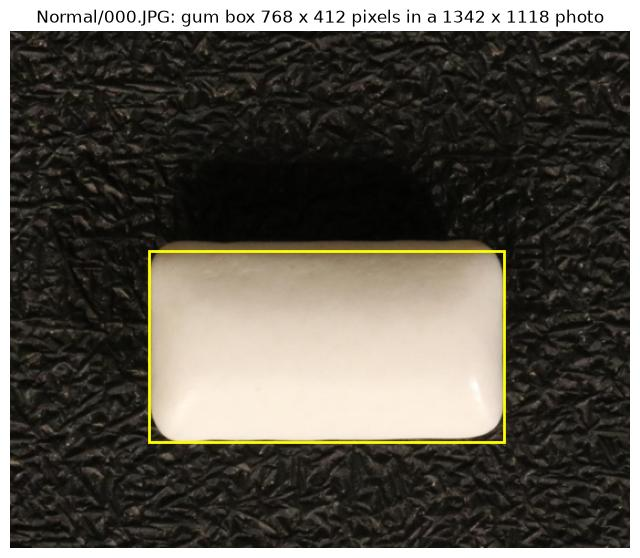

In [13]:
photo = photos[~photos["is_defect"]].iloc[0]
img = Image.open(os.path.join(RAW_DIR, photo["image"])).convert("RGB")
scale = SHOW_WIDTH / img.width

fig, ax = plt.subplots(figsize=(8, 6.8))
ax.imshow(img.resize((SHOW_WIDTH, round(img.height * scale))))
draw_box(ax, photo[["gum_left", "gum_top", "gum_right", "gum_bottom"]], "yellow", scale)
ax.set_title(f"{photo['name']}: gum box {photo['gum_width']} x {photo['gum_height']} pixels "
            f"in a {photo['photo_width']} x {photo['photo_height']} photo")
ax.axis("off")
plt.show()

> **What we see:**
>
> - All photos are 1342 x 1118 pixels.
> - The gum box is about 772 x 416 pixels (the median), and it covers only 21.5% of the photo on average. The other three quarters are mat.
> - The gum has nearly the same size in every photo: from 736 to 804 pixels wide and from 388 to 456 pixels high. So one window size can fit every gum.

## Step 2: The Gum Is a Bit Bigger Than Its Bright Box

### Brightness Across the Gum

> The light comes from below the gum. So:
>
> - the bottom of the gum is the brightest part, and its bottom edge is sharp,
> - the top of the gum is darker, and the mat just above the gum lies in the gum's shadow (almost black).
>
> The rule "brighter than 120" therefore misses a darker strip at the top of the gum. To measure it, we average the brightness of each row in the middle half of the gum (`dark_top_height()`).
>
> We show the normal train photo of split 1 with the tallest dark strip:
>
> - **Left:** the gum. Yellow: the gum box. Cyan: the real top edge of the gum, found by `dark_top_height()`. The white band is the middle half where we measure.
> - **Middle:** the brightness of each row, from top to bottom, along the white band. On the left is the shadow above the gum (almost 0). At the cyan line the brightness jumps up: here the gum starts, where the first row is brighter than 40 (red line). Then the brightness rises slowly towards the bottom of the gum. The gum box (yellow) only starts lower, where the gum is bright enough for the rule "brighter than 120" (orange line). The part between cyan and yellow is the dark top strip that the gum box misses.
>
>   The yellow line is not exactly where this curve passes 120, because `find_gum_box()` looks at the whole width of the gum in a smaller, smoothed photo, while this curve is the average of the middle band only.
> - **Right:** the brightness of each column, from left to right, across the middle of the gum. On the left and right, the brightness jumps straight from mat to gum, so the gum box fits the gum tightly there.

Normal/261.JPG: gum box top at row 464, real top edge at row 427, so the dark top strip is 37 pixels high


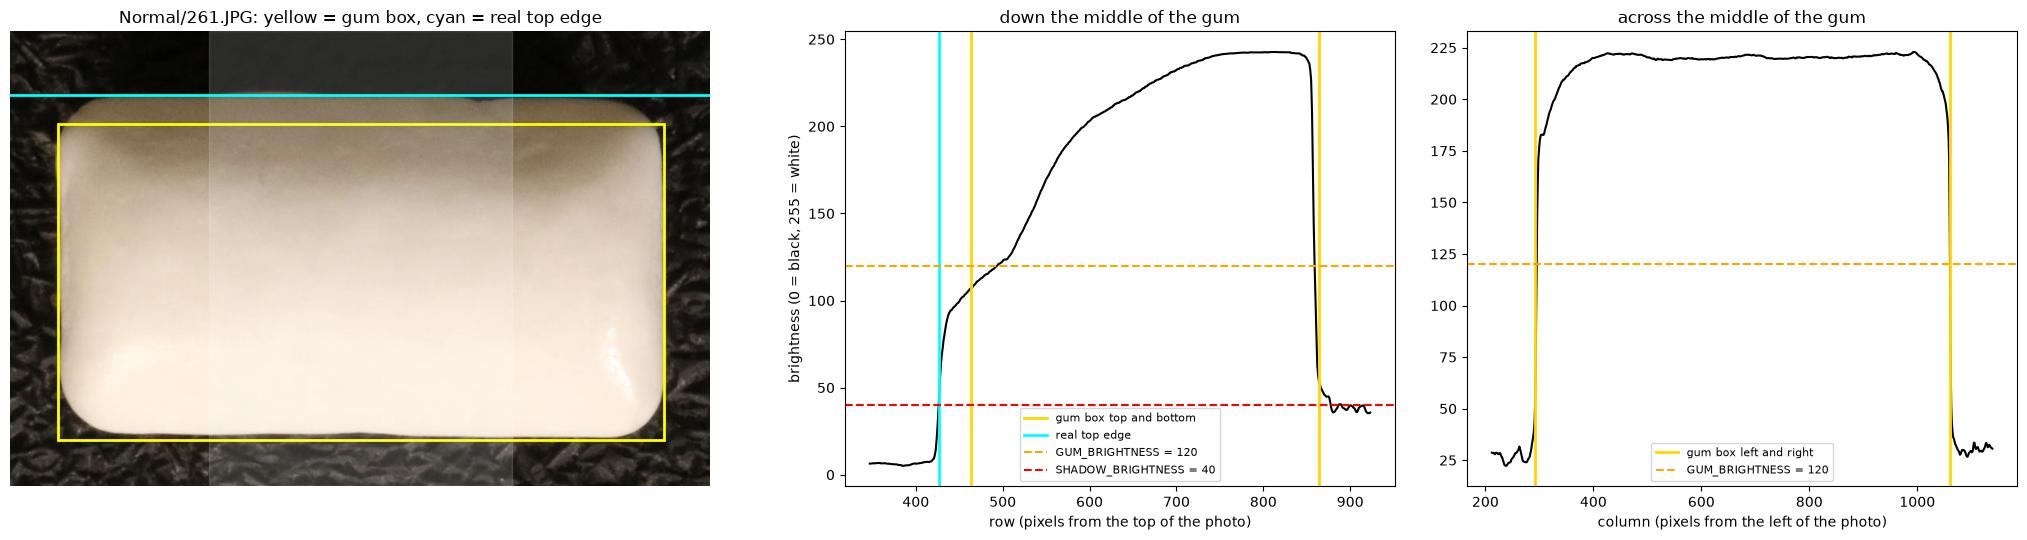

In [14]:
photo = photos.loc[photos.loc[photos["normal_train_1"], "dark_top"].idxmax()]
img = Image.open(os.path.join(RAW_DIR, photo["image"])).convert("RGB")
gray = np.asarray(img.convert("L"), dtype=float)
left, top, right, bottom = photo[["gum_left", "gum_top", "gum_right", "gum_bottom"]]
quarter_width, quarter_height = (right - left) // 4, (bottom - top) // 4
real_top = top - photo["dark_top"]
down = gray[:, left + quarter_width:right - quarter_width].mean(axis=1)
across = gray[top + quarter_height:bottom - quarter_height, :].mean(axis=0)
print(f"{photo['name']}: gum box top at row {top}, real top edge at row {real_top}, "
      f"so the dark top strip is {photo['dark_top']} pixels high")

view_left, view_top = left - 60, real_top - 80
fig, axes = plt.subplots(1, 3, figsize=(21, 5.5), gridspec_kw={"width_ratios": [1.5, 1, 1]})
axes[0].imshow(img.crop((view_left, view_top, right + 60, bottom + 60)))
draw_box(axes[0], (left - view_left, top - view_top, right - view_left, bottom - view_top), "yellow")
axes[0].axhline(real_top - view_top, color="cyan", linewidth=2)
axes[0].axvspan(left + quarter_width - view_left, right - quarter_width - view_left, color="white", alpha=0.15)
axes[0].set_title(f"{photo['name']}: yellow = gum box, cyan = real top edge")
axes[0].axis("off")

rows_shown = np.arange(real_top - 80, bottom + 60)
axes[1].plot(rows_shown, down[rows_shown], color="black")
axes[1].axvline(top, color="gold", linewidth=2, label="gum box top and bottom")
axes[1].axvline(bottom, color="gold", linewidth=2)
axes[1].axvline(real_top, color="cyan", linewidth=2, label="real top edge")
axes[1].axhline(GUM_BRIGHTNESS, color="orange", linestyle="--", label=f"GUM_BRIGHTNESS = {GUM_BRIGHTNESS}")
axes[1].axhline(SHADOW_BRIGHTNESS, color="red", linestyle="--", label=f"SHADOW_BRIGHTNESS = {SHADOW_BRIGHTNESS}")
axes[1].set_xlabel("row (pixels from the top of the photo)")
axes[1].set_ylabel("brightness (0 = black, 255 = white)")
axes[1].set_title("down the middle of the gum")
axes[1].legend(fontsize=8)

cols_shown = np.arange(left - 80, right + 80)
axes[2].plot(cols_shown, across[cols_shown], color="black")
axes[2].axvline(left, color="gold", linewidth=2, label="gum box left and right")
axes[2].axvline(right, color="gold", linewidth=2)
axes[2].axhline(GUM_BRIGHTNESS, color="orange", linestyle="--", label=f"GUM_BRIGHTNESS = {GUM_BRIGHTNESS}")
axes[2].set_xlabel("column (pixels from the left of the photo)")
axes[2].set_title("across the middle of the gum")
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

### How Tall Is the Dark Top Strip?

> The same measurement for all normal train photos of each split. `median`: half of the photos have a shorter strip. `tallest`: the biggest strip in that split.

In [15]:
for s in SPLITS:
    strip = photos.loc[photos[f"normal_train_{s}"], "dark_top"]
    print(f"Split {s}: dark top strip median {strip.median():.0f} pixels, tallest {strip.max()} pixels")

Split 1: dark top strip median 18 pixels, tallest 37 pixels
Split 2: dark top strip median 18 pixels, tallest 36 pixels
Split 3: dark top strip median 19 pixels, tallest 37 pixels


> **What we see:**
>
> - Down the middle (middle figure), the brightness rises slowly from the top of the gum to its bottom. The gum box only starts where the gum is brighter than 120, so in this photo it misses the top 37 pixels of the gum.
> - Across the middle (right figure), the brightness jumps from mat to gum in a few pixels, so on the left and the right the gum box fits the gum.
> - In every split, the dark top strip is at most 37 pixels high. Our `MARGIN` of 64 pixels covers it, with room to spare.

## Step 3: Choose One Window Size

### The Rule

> The window must hold the biggest gum, with `MARGIN` pixels around it on every side:
>
> - *window width = biggest gum width + 2 × MARGIN, rounded up to a multiple of 32*
> - *window height = biggest gum height + 2 × MARGIN, rounded up to a multiple of 32*
>
> We measure the biggest gum **only on the normal train photos** of each split, the photos PatchCore learns from. No validation photo, no test photo and no mask decides the window size. If the three splits gave different sizes, we would take the biggest, so that one size fits all splits.
>
> Why one size for all photos? Then every crop has the same size, and the gum keeps its real size in pixels in every crop: nothing is stretched or squeezed. A defect looks the same size in every photo, which makes it easier for both models to learn what normal looks like.
>
> At the end, the code halves the window 5 times, the way YOLO does inside its network (see **Multiple of 32** in Words). `size // 2**n` is the size after halving `n` times: `2**n` means 2 to the power `n` (1, 2, 4, 8, 16, 32), and `//` divides without decimals.

In [16]:
window_widths, window_heights = [], []
for s in SPLITS:
      used = photos[photos[f"normal_train_{s}"]]
      width, height = used["gum_width"].max(), used["gum_height"].max()
      window_widths.append(round_up(width + 2 * MARGIN, SIZE_STEP))
      window_heights.append(round_up(height + 2 * MARGIN, SIZE_STEP))
      print(f"Split {s} ({len(used)} normal train photos): "
          f"width {width} + 2 x {MARGIN} = {width + 2 * MARGIN} -> {window_widths[-1]} | "
          f"height {height} + 2 x {MARGIN} = {height + 2 * MARGIN} -> {window_heights[-1]}")

WINDOW_SIZE = (max(window_widths), max(window_heights))
photo_area = photos["photo_width"].iloc[0] * photos["photo_height"].iloc[0]
print(f"\nWindow size for all photos: {WINDOW_SIZE[0]} x {WINDOW_SIZE[1]} pixels "
      f"({WINDOW_SIZE[0] * WINDOW_SIZE[1] / photo_area:.1%} of the photo)")
print(f"In multiples of {SIZE_STEP}: {WINDOW_SIZE[0] // SIZE_STEP} x {SIZE_STEP} and {WINDOW_SIZE[1] // SIZE_STEP} x {SIZE_STEP}")

print("\nHalving the window 5 times, the way YOLO does inside its network:")
for name, size in zip(["width", "height"], WINDOW_SIZE):
    print(f"{name}: " + " -> ".join(str(size // 2**n) for n in range(6)))

Split 1 (347 normal train photos): width 796 + 2 x 64 = 924 -> 928 | height 456 + 2 x 64 = 584 -> 608
Split 2 (347 normal train photos): width 796 + 2 x 64 = 924 -> 928 | height 456 + 2 x 64 = 584 -> 608
Split 3 (347 normal train photos): width 796 + 2 x 64 = 924 -> 928 | height 456 + 2 x 64 = 584 -> 608

Window size for all photos: 928 x 608 pixels (37.6% of the photo)
In multiples of 32: 29 x 32 and 19 x 32

Halving the window 5 times, the way YOLO does inside its network:
width: 928 -> 464 -> 232 -> 116 -> 58 -> 29
height: 608 -> 304 -> 152 -> 76 -> 38 -> 19


> **What we see:** in all three splits the biggest normal train gum is 796 x 456 pixels, so all three give the same window: 796 + 2 × 64 = 924, rounded up to 928 (29 × 32), and 456 + 2 × 64 = 584, rounded up to 608 (19 × 32). The window keeps 37.6% of the photo, and it still holds the whole gum with space around it. Halved 5 times, the window becomes 29 x 19 without anything left over at any step, so YOLO can use it as it is.

## Step 4: Place the Window on Every Photo

### Place and Measure

> For every photo we place the window with `place_window()`, with the middle of the window on the middle of the gum box. Then we measure:
>
> - how many windows had to be moved to stay inside the photo,
> - the smallest space between the gum box and the window edge, on each side, over all photos.
>
> Here we use all photos, also defect and test photos: every photo needs its own window. The window size stays the one from Step 3.

In [17]:
windows = [place_window((p["gum_left"], p["gum_top"], p["gum_right"], p["gum_bottom"]), WINDOW_SIZE,
                        (p["photo_width"], p["photo_height"])) for _, p in photos.iterrows()]
photos[["crop_left", "crop_top", "crop_right", "crop_bottom"]] = np.array(windows, dtype=int)

centred_left = (photos["gum_left"] + photos["gum_right"]) // 2 - WINDOW_SIZE[0] // 2
centred_top = (photos["gum_top"] + photos["gum_bottom"]) // 2 - WINDOW_SIZE[1] // 2
moved = (photos["crop_left"] != centred_left) | (photos["crop_top"] != centred_top)
inside = ((photos["crop_left"] >= 0) & (photos["crop_top"] >= 0)
            & (photos["crop_right"] <= photos["photo_width"]) & (photos["crop_bottom"] <= photos["photo_height"]))
space = {"left": photos["gum_left"] - photos["crop_left"], "right": photos["crop_right"] - photos["gum_right"],
            "top": photos["gum_top"] - photos["crop_top"], "bottom": photos["crop_bottom"] - photos["gum_bottom"]}

print(f"Windows inside their photo: {inside.sum()} of {len(photos)}")
print(f"Windows that had to be moved to stay inside the photo: {moved.sum()} of {len(photos)}")
print("Smallest space between gum box and window edge: "
      + ", ".join(f"{side} {values.min()}" for side, values in space.items()) + " pixels")
print(f"Tallest dark top strip in all photos: {photos['dark_top'].max()} pixels")

Windows inside their photo: 603 of 603
Windows that had to be moved to stay inside the photo: 0 of 603
Smallest space between gum box and window edge: left 62, right 62, top 76, bottom 76 pixels
Tallest dark top strip in all photos: 37 pixels


### Look at the Windows

> Six photos, chosen to show the extremes: the gum furthest to the left, right, top and bottom of the photo, the widest gum box and the tallest gum box. Yellow: the gum box. Cyan: the window that will be cut out.

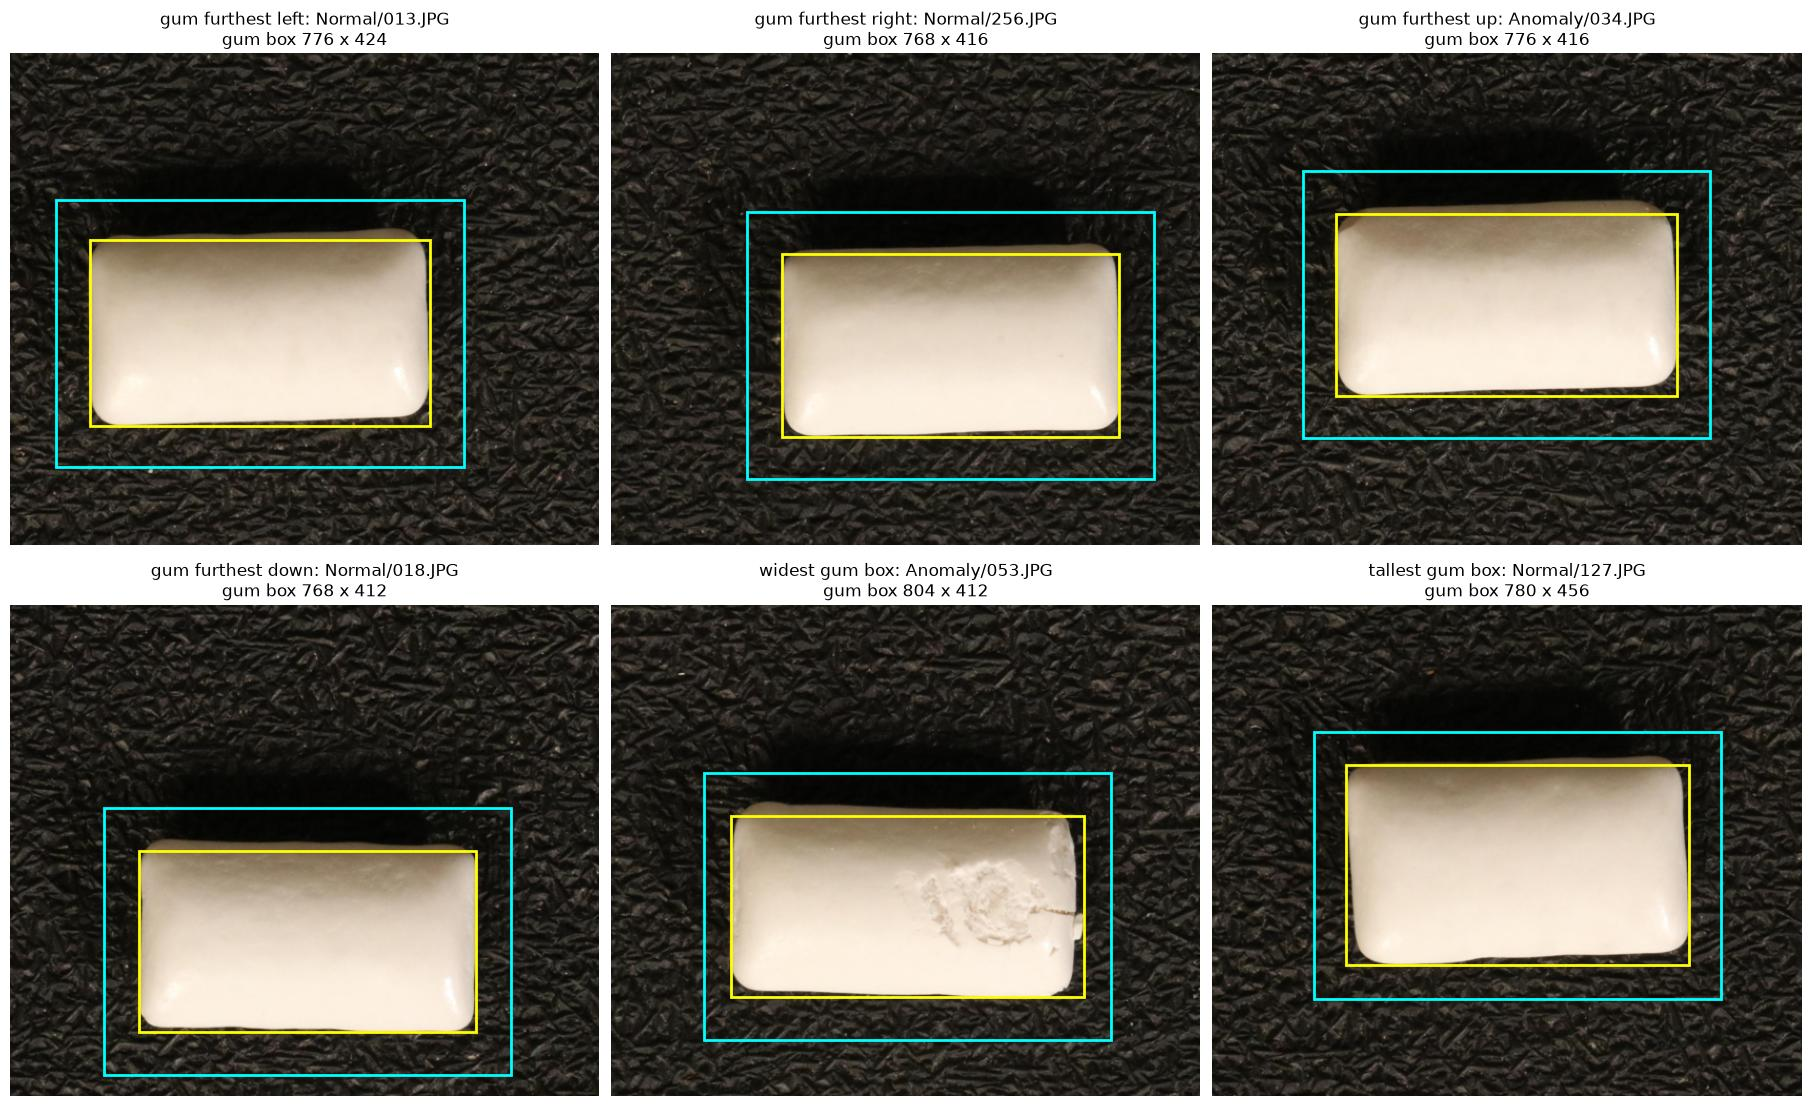

In [18]:
centre_x = (photos["gum_left"] + photos["gum_right"]) / 2
centre_y = (photos["gum_top"] + photos["gum_bottom"]) / 2
examples = {"gum furthest left": centre_x.idxmin(), "gum furthest right": centre_x.idxmax(),
            "gum furthest up": centre_y.idxmin(), "gum furthest down": centre_y.idxmax(),
            "widest gum box": photos["gum_width"].idxmax(), "tallest gum box": photos["gum_height"].idxmax()}

fig, axes = plt.subplots(2, 3, figsize=(18, 11), layout="constrained")
for ax, (title, i) in zip(axes.ravel(), examples.items()):
    photo = photos.loc[i]
    img = Image.open(os.path.join(RAW_DIR, photo["image"])).convert("RGB")
    scale = SHOW_WIDTH / img.width
    ax.imshow(img.resize((SHOW_WIDTH, round(img.height * scale))))
    draw_box(ax, photo[["gum_left", "gum_top", "gum_right", "gum_bottom"]], "yellow", scale)
    draw_box(ax, photo[["crop_left", "crop_top", "crop_right", "crop_bottom"]], "cyan", scale)
    ax.set_title(f"{title}: {photo['name']}\ngum box {photo['gum_width']} x {photo['gum_height']}")
    ax.axis("off")
plt.show()

> **What we see:**
>
> - The window follows the gum: wherever the gum lies, it sits in the middle of its window.
> - All 603 windows fit inside their photo, and none had to be moved.
> - On the left and right there are at least 62 pixels between gum box and window edge. The smallest space belongs to the widest gum (804 pixels, a defect photo with a broken gum), which is wider than any normal train gum.
> - At the top there are at least 76 pixels, much more than the tallest dark top strip (37 pixels). So the darker top of the gum is always inside the window.

## Step 5: Check With the Masks That No Defect Is Cut Off

### Count the Defect Pixels Outside the Window

> This is the first time this notebook opens the masks, and it only uses them to **check**. The window was already fixed in Step 3 and Step 4, without masks.
>
> For every defect photo we count the defect pixels (mask number above 0) that lie outside its window. `inside` is a map of the photo that is `True` inside the window, so `defect & ~inside` keeps the defect pixels outside the window (`~` means "not").

In [19]:
rows = []
for i, photo in tqdm(photos[photos["is_defect"]].iterrows(), total=photos["is_defect"].sum(),
                    desc="Checking the masks"):
    mask = np.asarray(Image.open(os.path.join(RAW_DIR, photo["mask"])))
    inside = np.zeros(mask.shape, dtype=bool)
    inside[photo["crop_top"]:photo["crop_bottom"], photo["crop_left"]:photo["crop_right"]] = True
    defect = mask > 0
    rows.append({"photo": i, "name": photo["name"], "defect pixels": int(defect.sum()),
                "pixels outside the window": int((defect & ~inside).sum())})
mask_check = pd.DataFrame(rows).set_index("photo")

print(f"Defect photos checked: {len(mask_check)}")
print(f"Defect pixels in all masks: {mask_check['defect pixels'].sum():,}")
print(f"Defect photos with pixels outside the window: {(mask_check['pixels outside the window'] > 0).sum()}")
print(f"Defect pixels outside the window: {mask_check['pixels outside the window'].sum()}")

Checking the masks: 100%|██████████| 100/100 [00:00<00:00, 139.91it/s]

Defect photos checked: 100
Defect pixels in all masks: 1,271,411
Defect photos with pixels outside the window: 1
Defect pixels outside the window: 3


### Look at the Pixels Outside the Window

> For every photo with defect pixels outside its window, the table shows the piece of the mask they belong to (a piece = defect pixels that touch each other):
>
> - `defect type`: the defect type of that piece, from its mask number.
> - `piece size`: how many pixels the whole piece has. Fewer than `SPECK_PIXELS` (10) means it is a speck.
> - `distance from the gum box`: how far the piece lies from the gum box, in pixels.

In [20]:
cut_photos = mask_check.index[mask_check["pixels outside the window"] > 0]
rows = []
for i in cut_photos:
    photo = photos.loc[i]
    mask = np.asarray(Image.open(os.path.join(RAW_DIR, photo["mask"])))
    inside = np.zeros(mask.shape, dtype=bool)
    inside[photo["crop_top"]:photo["crop_bottom"], photo["crop_left"]:photo["crop_right"]] = True
    pieces, n_pieces = ndimage.label(mask > 0, structure=TOUCHING)
    for piece in np.unique(pieces[(mask > 0) & ~inside]):
        piece_rows, piece_cols = np.nonzero(pieces == piece)
        distance = max(photo["gum_left"] - piece_cols.max() - 1, piece_cols.min() - photo["gum_right"],
                        photo["gum_top"] - piece_rows.max() - 1, piece_rows.min() - photo["gum_bottom"], 0)
        rows.append({"photo": photo["name"], "defect type": MASK_CODE[mask[piece_rows[0], piece_cols[0]]],
                    "piece size": len(piece_rows), "pixels outside the window": int((~inside[pieces == piece]).sum()),
                    "distance from the gum box": int(distance), "is a speck": len(piece_rows) < SPECK_PIXELS,
                    "row": int(piece_rows.mean()), "column": int(piece_cols.mean())})
cut_pieces = pd.DataFrame(rows)
cut_pieces

,photo,defect type,piece size,pixels outside the window,distance from the gum box,is a speck,row,column
0,Anomaly/080.JPG,small cracks,3,3,122,True,863,1174


> The figure shows the first of these photos:
>
> - **Left:** the whole photo. Yellow: the gum box. Cyan: the window. The red circle marks the pixels outside the window.
> - **Middle:** a close-up of those pixels, 61 x 61 pixels of the photo, as they are.
> - **Right:** the same close-up, with the mask pixels painted red.

Close-up: 61 x 61 pixels around the pixels outside the window


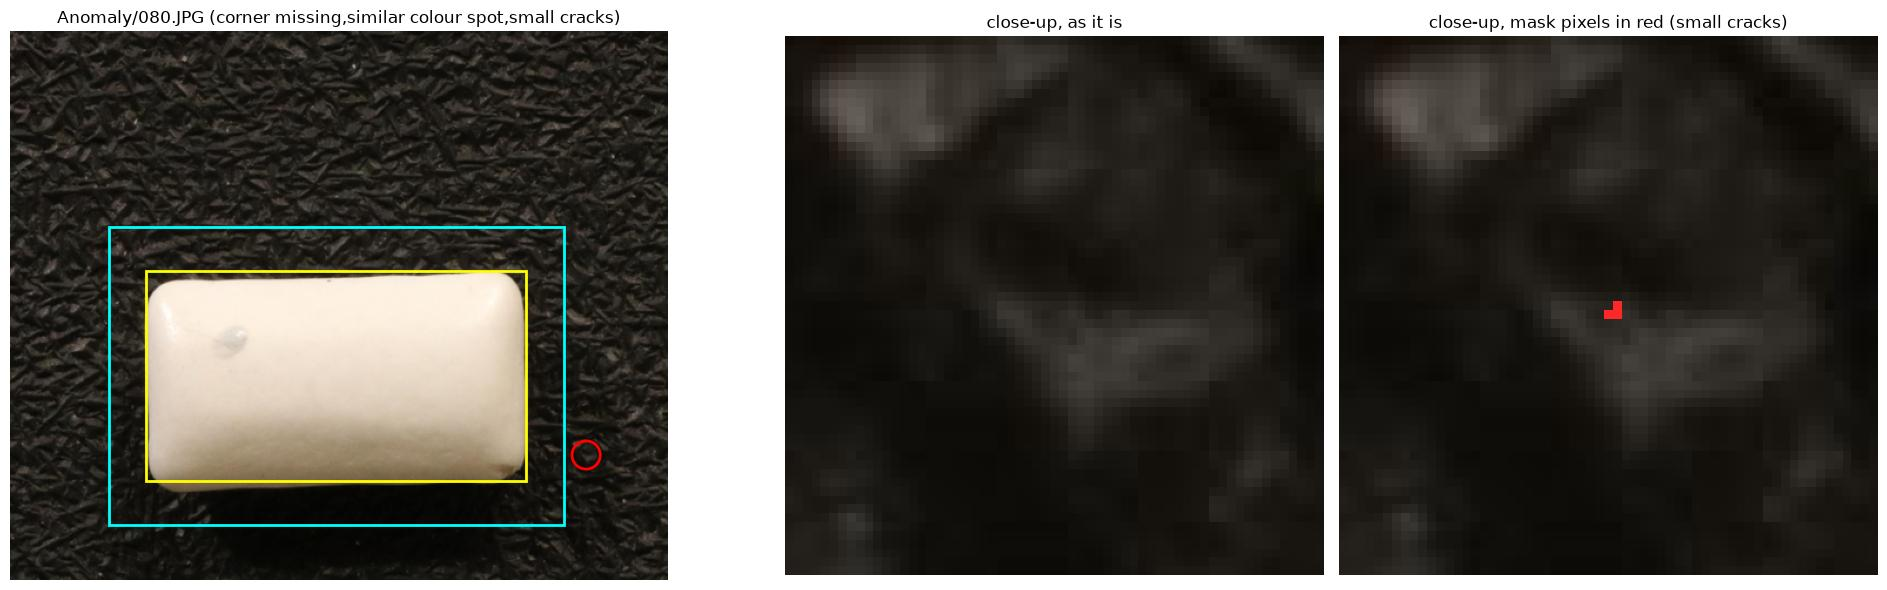

In [21]:
piece = cut_pieces.iloc[0]
photo = photos[photos["name"] == piece["photo"]].iloc[0]
img = Image.open(os.path.join(RAW_DIR, photo["image"])).convert("RGB")
mask = np.asarray(Image.open(os.path.join(RAW_DIR, photo["mask"])))
scale = SHOW_WIDTH / img.width
close = (piece["column"] - 30, piece["row"] - 30, piece["column"] + 31, piece["row"] + 31)
close_up = np.asarray(img.crop(close))
print(f"Close-up: {close[2] - close[0]} x {close[3] - close[1]} pixels around the pixels outside the window")
painted = close_up.copy()
painted[mask[close[1]:close[3], close[0]:close[2]] > 0] = [255, 40, 40]

fig, axes = plt.subplots(1, 3, figsize=(20, 6), gridspec_kw={"width_ratios": [1.6, 1, 1]})
axes[0].imshow(img.resize((SHOW_WIDTH, round(img.height * scale))))
draw_box(axes[0], photo[["gum_left", "gum_top", "gum_right", "gum_bottom"]], "yellow", scale)
draw_box(axes[0], photo[["crop_left", "crop_top", "crop_right", "crop_bottom"]], "cyan", scale)
axes[0].add_patch(Circle((piece["column"] * scale, piece["row"] * scale), radius=12, fill=False,
                        edgecolor="red", linewidth=2))
axes[0].set_title(f"{photo['name']} ({photo['label']})")
axes[1].imshow(close_up, interpolation="nearest")
axes[1].set_title("close-up, as it is")
axes[2].imshow(painted, interpolation="nearest")
axes[2].set_title(f"close-up, mask pixels in red ({piece['defect type']})")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

> **What we see:**
>
> - Only 3 of all defect pixels lie outside a window, in one photo: Anomaly/080.JPG.
> - They form one piece of *small cracks* of only 3 pixels, on the mat, 122 pixels to the right of the gum box. The close-up shows only mat there, no crack. Most likely the pen slipped when this mask was drawn.
> - A piece of 3 pixels is a speck (fewer than `SPECK_PIXELS` = 10 pixels), and notebook 3.2 drops specks anyway. All the real defects of this photo lie inside its window.
>
> So the window cuts off no real defect. If this check had cut off a real defect, we would have had to change the rule after looking at the masks. That is why the margin was chosen generously in Steps 2 and 3, before this check.

## Step 6: Cut and Save

### Save the Crops, the Masks and the Table

> For every photo:
>
> 1. Open the photo, cut out its window (`.crop()`) and save it as PNG in `images/Normal/` or `images/Anomaly/`.
> 2. For a defect photo, cut its mask with **the same window** and save it in `masks/Anomaly/`. The mask stays a table of numbers (0 = no defect, 1 to 5 = defect type), only smaller.
> 3. Write one row in `crop_boxes.csv`.
>
> `crop_boxes.csv` has one row per photo, with these columns:
>
> - `image`: the original photo, the same path as in the split files, so the two tables can be joined.
> - `crop_image`, `crop_mask`: the saved crop and cropped mask, inside `data/processed/crops/`. `crop_mask` is empty for normal photos.
> - `gum_left`, `gum_top`, `gum_right`, `gum_bottom`: the gum box in the original photo.
> - `crop_left`, `crop_top`, `crop_right`, `crop_bottom`: the window in the original photo.
>
> Running this cell again replaces the files with the same files.

In [22]:
for folder in ["images/Normal", "images/Anomaly", "masks/Anomaly"]:
    os.makedirs(full_path(CROP_DIR, folder), exist_ok=True)

rows = []
for i, photo in tqdm(photos.iterrows(), total=len(photos), desc="Cutting and saving"):
    window = tuple(int(v) for v in photo[["crop_left", "crop_top", "crop_right", "crop_bottom"]])
    crop_image = crop_path(photo["image"], "images")
    Image.open(os.path.join(RAW_DIR, photo["image"])).convert("RGB").crop(window).save(full_path(CROP_DIR, crop_image))
    crop_mask = ""
    if photo["is_defect"]:
        crop_mask = crop_path(photo["mask"], "masks")
        Image.open(os.path.join(RAW_DIR, photo["mask"])).crop(window).save(full_path(CROP_DIR, crop_mask))
    rows.append({"image": photo["image"], "crop_image": crop_image, "crop_mask": crop_mask,
                 **photo[["gum_left", "gum_top", "gum_right", "gum_bottom",
                        "crop_left", "crop_top", "crop_right", "crop_bottom"]].to_dict()})
crop_table = pd.DataFrame(rows)
crop_table.to_csv(CROP_TABLE_FILE, index=False)

image_mb = sum(os.path.getsize(full_path(CROP_DIR, p)) for p in crop_table["crop_image"]) / 1024**2
mask_paths = crop_table.loc[crop_table["crop_mask"] != "", "crop_mask"]
mask_mb = sum(os.path.getsize(full_path(CROP_DIR, p)) for p in mask_paths) / 1024**2
print(f"Saved {len(crop_table)} crops and {len(mask_paths)} cropped masks in data/processed/crops/")
print(f"Space used: crops {image_mb:.0f} MB, masks {mask_mb:.1f} MB")
crop_table.head(3)

Cutting and saving: 100%|██████████| 603/603 [00:28<00:00, 21.03it/s]

Saved 603 crops and 100 cropped masks in data/processed/crops/
Space used: crops 171 MB, masks 0.1 MB


,image,crop_image,crop_mask,gum_left,gum_top,gum_right,gum_bottom,crop_left,crop_top,crop_right,crop_bottom
0,chewinggum/Data/Images/Normal/000.JPG,images/Normal/000.png,,300,476,1068,888,220,378,1148,986
1,chewinggum/Data/Images/Normal/001.JPG,images/Normal/001.png,,260,436,1044,876,188,352,1116,960
2,chewinggum/Data/Images/Normal/002.JPG,images/Normal/002.png,,264,428,1040,836,188,328,1116,936


### Quick Check of One Crop

> We open one saved crop again and compare it, pixel by pixel, with the window of the original photo. PNG keeps every pixel, so they must be exactly the same. Notebook 3.3 does this for every photo and every mask.

In [23]:
row = crop_table.iloc[0]
saved = np.asarray(Image.open(full_path(CROP_DIR, row["crop_image"])))
original = np.asarray(Image.open(os.path.join(RAW_DIR, row["image"])).convert("RGB"))
window = original[row["crop_top"]:row["crop_bottom"], row["crop_left"]:row["crop_right"]]
print(f"{short_name(row['image'])} -> {row['crop_image']}: size {saved.shape[1]} x {saved.shape[0]}, "
      f"same pixels as the original window: {np.array_equal(saved, window)}")

Normal/000.JPG -> images/Normal/000.png: size 928 x 608, same pixels as the original window: True


### Look at Some Crops

> This is what the models will see. Top row: three normal crops. Bottom row: three defect crops, with the edge of the defect drawn in red from the cropped mask. The edge is the defect pixels that disappear when the defect is made 2 pixels thinner on every side (`binary_erosion`).
>
> `label_of` looks up the label of a photo (like `corner missing,small cracks`) by its path. We use it here and in Step 7.

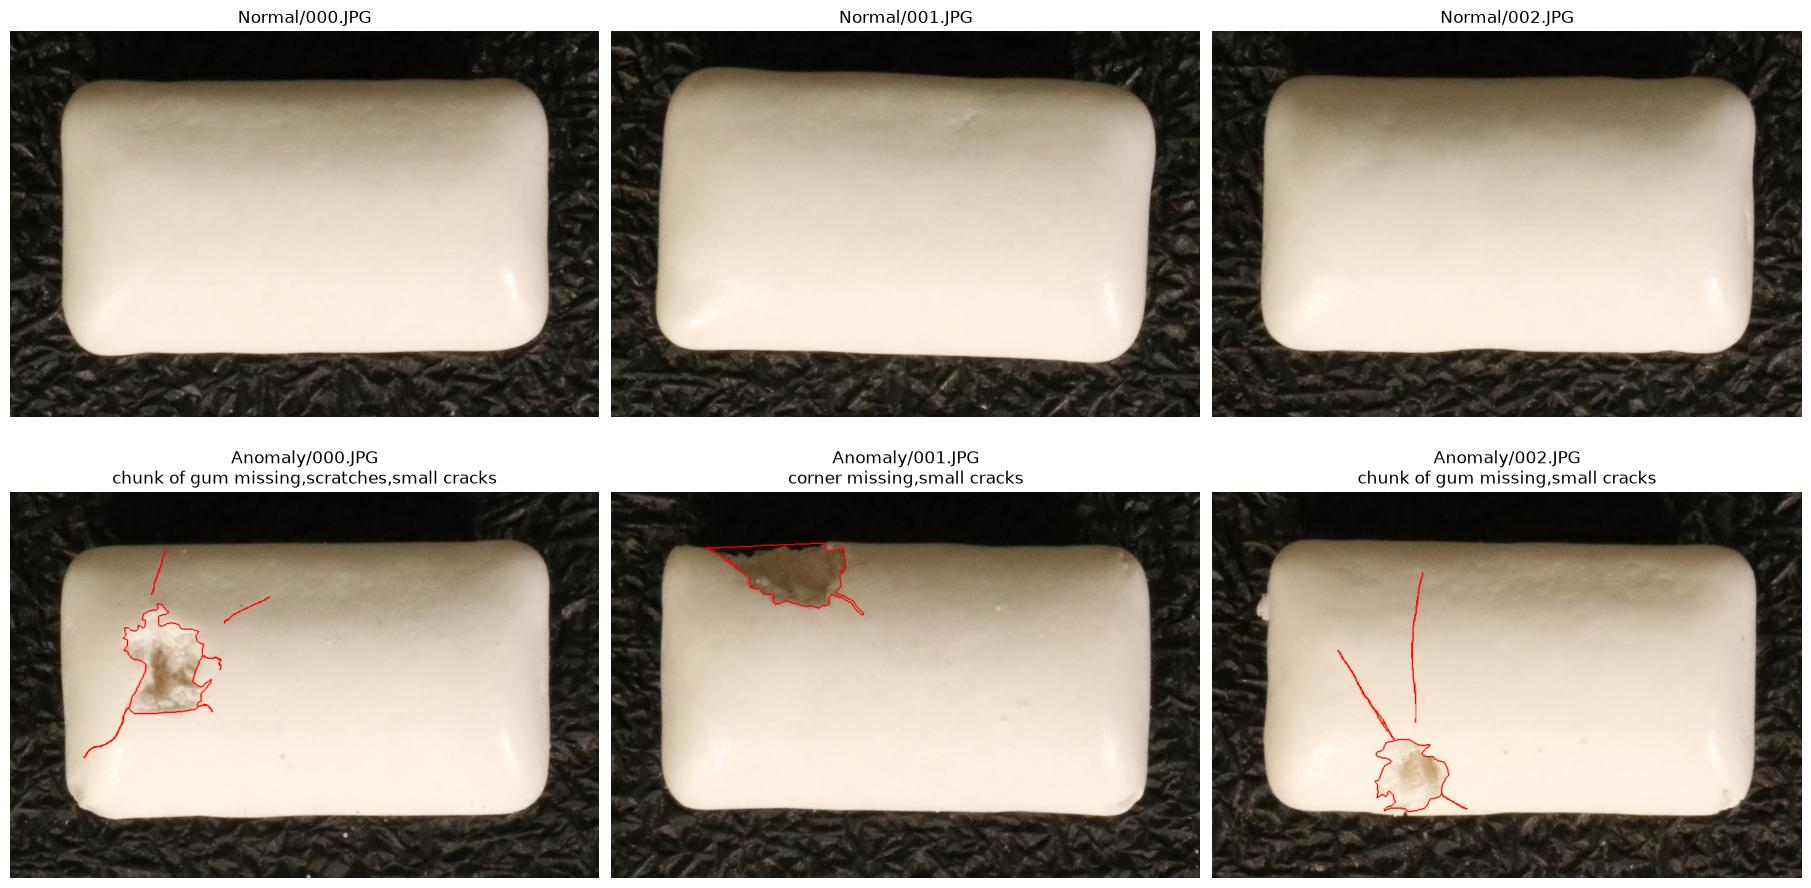

In [24]:
label_of = dict(zip(photos["image"], photos["label"]))
shown = pd.concat([crop_table[crop_table["crop_mask"] == ""].head(3), crop_table[crop_table["crop_mask"] != ""].head(3)])

fig, axes = plt.subplots(2, 3, figsize=(18, 9), layout="constrained")
for ax, (_, row) in zip(axes.ravel(), shown.iterrows()):
    crop = np.asarray(Image.open(full_path(CROP_DIR, row["crop_image"]))).copy()
    title = short_name(row["image"])
    if row["crop_mask"]:
        defect = np.asarray(Image.open(full_path(CROP_DIR, row["crop_mask"]))) > 0
        crop[defect & ~ndimage.binary_erosion(defect, iterations=2)] = [255, 0, 0]
        title += "\n" + label_of[row["image"]]
    ax.imshow(crop)
    ax.set_title(title)
    ax.axis("off")
plt.show()

## Step 7: What the Crop Gains

### The Same Crack at Three Picture Sizes

> A model looks at pictures of a fixed size, often much smaller than the photo. Here we compare two ways to get a picture of a given width:
>
> - **Top row:** shrink the **whole photo** to that width.
> - **Bottom row:** shrink the **crop** to that width.
>
> The columns are three widths: the full crop width (928), one half (464) and one quarter (232). In every panel we show the same small area around a crack, enlarged to the same size on screen, so you can count its pixels.
>
> The crack is a typical one: of all photos with *small cracks*, the one with the median number of crack pixels in its cropped mask. Its thickness is measured with `distance_transform_edt()`: for every crack pixel, the distance to the nearest pixel that is not crack. The middle of the crack has the biggest distance, about half the thickness, so *thickness ≈ 2 × biggest distance*.

Photo: Anomaly/004.JPG | crack pixels: 419 | crack thickness: about 4.0 pixels


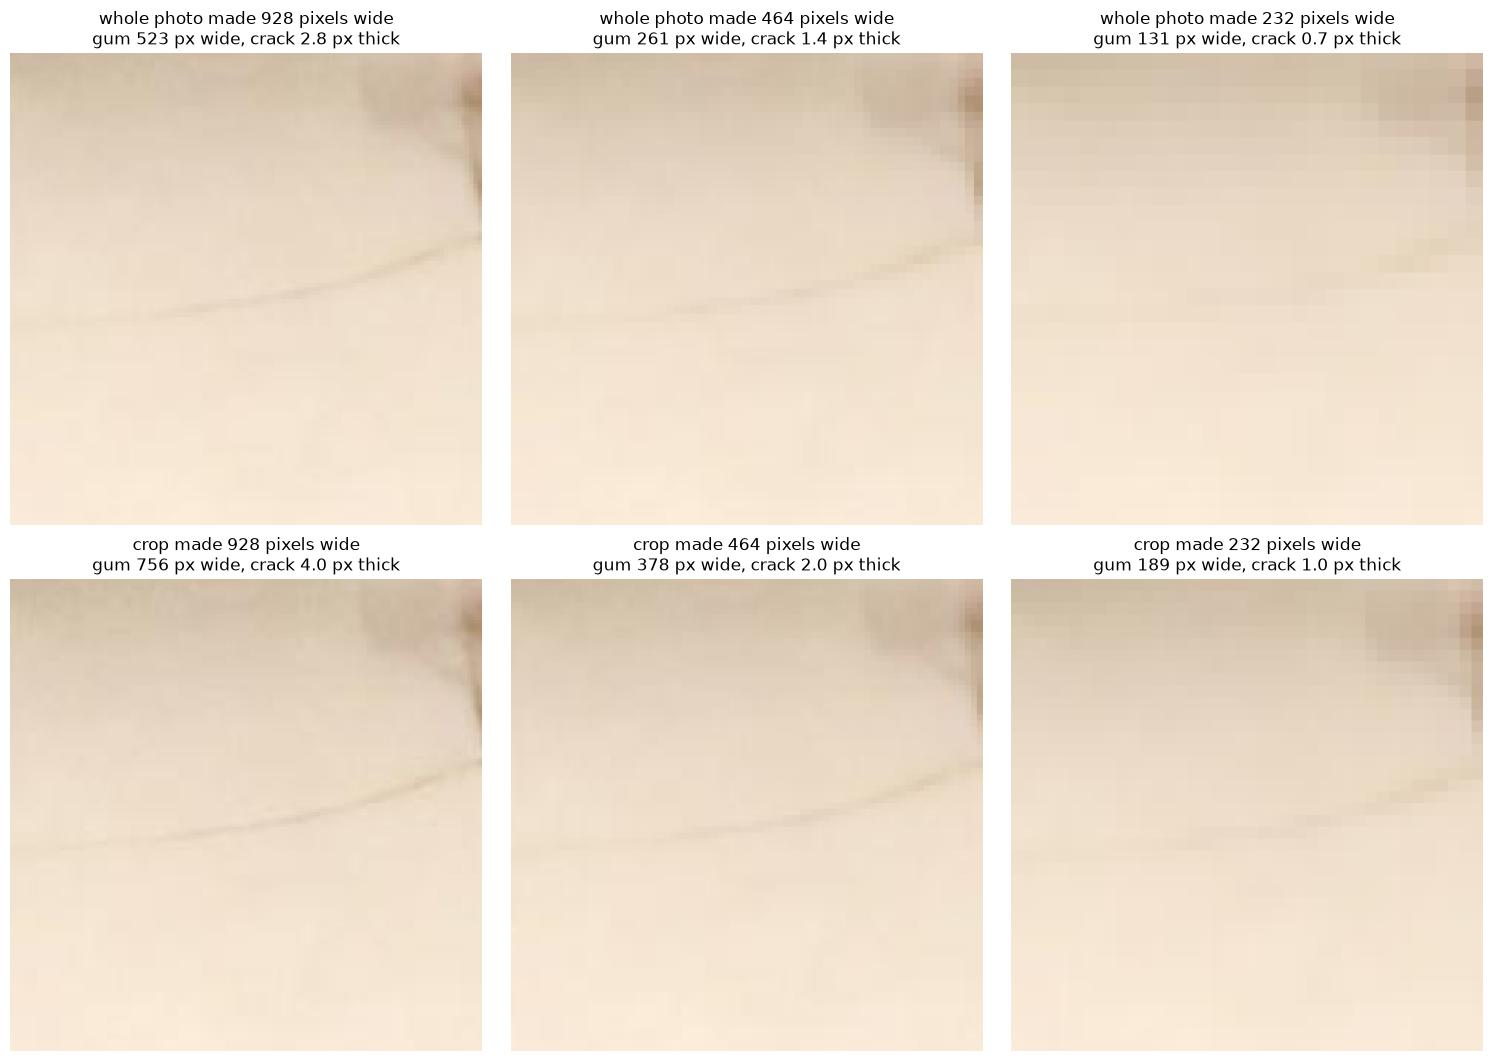

At the same picture width, the crop shows the gum 1.45 times wider (1342 / 928)


gum width (pixels)             crack thickness (pixels)  \
picture                     crop whole photo                     crop   
picture width                                                           
928                          756         523                      4.0   
464                          378         261                      2.0   
232                          189         131                      1.0   

                           
picture       whole photo  
picture width              
928                   2.8  
464                   1.4  
232                   0.7

In [25]:
has_cracks = crop_table["image"].map(label_of).str.contains("small cracks")
crack_sizes = []
for i, row in crop_table[has_cracks].iterrows():
    crack = np.asarray(Image.open(full_path(CROP_DIR, row["crop_mask"]))) == TYPE_CODE["small cracks"]
    crack_sizes.append((int(crack.sum()), i))
crack_sizes.sort()
n_crack_pixels, chosen = crack_sizes[len(crack_sizes) // 2]
row = crop_table.loc[chosen]
crack = np.asarray(Image.open(full_path(CROP_DIR, row["crop_mask"]))) == TYPE_CODE["small cracks"]
thickness = 2 * ndimage.distance_transform_edt(crack).max()
crack_rows, crack_cols = np.nonzero(crack)
centre_x, centre_y = int(crack_cols.mean()), int(crack_rows.mean())
gum_width = row["gum_right"] - row["gum_left"]
print(f"Photo: {short_name(row['image'])} | crack pixels: {n_crack_pixels} | crack thickness: about {thickness:.1f} pixels")

whole = Image.open(os.path.join(RAW_DIR, row["image"])).convert("RGB")
crop = Image.open(full_path(CROP_DIR, row["crop_image"]))
pictures = {"whole photo": (whole, centre_x + row["crop_left"], centre_y + row["crop_top"]),
            "crop": (crop, centre_x, centre_y)}
half_side = 80

fig, axes = plt.subplots(2, len(SHRINK_FACTORS), figsize=(15, 10.5), layout="constrained")
table = []
for col, factor in enumerate(SHRINK_FACTORS):
    width = WINDOW_SIZE[0] // factor
    for line, (kind, (picture, x, y)) in enumerate(pictures.items()):
        scale = width / picture.width
        small = picture.resize((width, round(picture.height * scale)), Image.BILINEAR)
        area = [round(v * scale) for v in (x - half_side, y - half_side, x + half_side, y + half_side)]
        axes[line, col].imshow(small.crop(area).resize((320, 320), Image.NEAREST))
        axes[line, col].set_title(f"{kind} made {width} pixels wide\ngum {gum_width * scale:.0f} px wide, "
                                  f"crack {thickness * scale:.1f} px thick")
        axes[line, col].axis("off")
        table.append({"picture width": width, "picture": kind, "gum width (pixels)": round(gum_width * scale),
                      "crack thickness (pixels)": round(thickness * scale, 1)})
plt.show()

print(f"At the same picture width, the crop shows the gum {whole.width / crop.width:.2f} times wider "
        f"({whole.width} / {crop.width})")
pd.DataFrame(table).pivot(index="picture width", columns="picture").sort_index(ascending=False)

> **What we see:**
>
> - At the same picture width, the gum and its defects are 1.45 times bigger in the crop than in the whole photo, because the crop throws the mat away first. At 464 pixels wide, for example, the gum is 378 pixels wide in the crop but only 261 in the whole photo.
> - This crack is about 4.0 pixels thick in the original photo. At half size it is still 2.0 pixels thick in the crop (1.4 in the whole photo), and easy to see. At a quarter size it is only 1.0 pixel thick in the crop and 0.7 in the whole photo: it almost disappears.
>
> So in step 4 we will not shrink the crops to a quarter. This notebook keeps the crops at full size, and each model chooses its own picture size in step 4.

## Summary

> **What this notebook did**
>
> - Found the gum in all 603 photos. The gum box misses the darker top of the gum, at most 37 pixels in the normal train photos.
> - Chose one window size from the normal train photos only: biggest gum + 64 pixels on every side, rounded up to a multiple of 32. All three splits give 928 x 608 pixels (37.6% of the photo).
> - Placed the window on the gum of every photo. All windows fit in their photo. The rule needs no mask and no label, so the demo in step 6 can crop a new photo in exactly the same way.
> - Checked with the masks: no real defect is cut off. Only a 3-pixel speck on the mat of Anomaly/080.JPG lies outside its window.
> - Saved 603 crops and 100 cropped masks as PNG, and `crop_boxes.csv`.
>
> **What this notebook does not do, and why**
>
> - **No resizing:** each model chooses its own picture size in step 4. Step 7 showed that a quarter size is too small for thin cracks.
> - **No changes to colour or brightness:** each model scales the pixel values in its own way in step 4. Changing the photos here could also make faint defects, like *similar colour spot*, harder to see.
> - **No augmentation** (random flips, turns, colour changes): YOLO does this by itself while it trains, with new random changes every time. PatchCore learns from the normal photos as they are.
> - **No rotation:** the gum always lies straight, so there is nothing to straighten.
>
> **Next:** `notebooks/3_preprocessing/3.2_make_yolo_labels.ipynb`